# 基于尾部相关的分层聚类配置

**缘起**：整理稿 4.2.1 节记载了东北证券（2025）的一套方法 —— 用两两 Clayton 下尾相关构造距离、
Ward 法聚类，再沿树用一个 arctan 公式逐层合成组合尾部风险并最小化。
**未能取得原文**，公式无法核对是否抄写准确，因此本研究不称为复现，而是检验这类方法的三个核心环节：

| 部分 | 问题 |
|---|---|
| A | 用下尾相关 λ_L 构造的距离，和普通相关系数距离有多大不同？ |
| B | arctan 两资产合成公式能多准确地给出组合的真实 ES？比不用尾部信息的公式好吗？ |
| C | 样本外，基于尾部相关的配置是否比基于普通相关的、或直接最小化 ES 的配置更好？ |

**数据**：整理稿示例中的 10 只 ETF（后复权、含分红再投资），共同区间 2016-11 起（中证1000ETF 上市最晚）。

**整理稿方法中未说明、本研究的取法**（详见 `tailrisk/allocation.py` 开头）：
单资产 TR 用 95% 历史 ES（GPD 作稳健性）；公式中的 w1、w2 取两簇在节点内的相对权重；
两簇之间的距离取成员两两距离的平均；λ_L=0 时截断于 1e-4。权重上下限按整理稿取 0.01%–20%。

## 0 · 环境与数据

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from scipy.stats import norm, spearmanr
%run ../../01_methods.ipynb

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

prices = load_prices(ETF10)
R = to_returns(prices).dropna()
LOOKBACK = 250
month_ends = R.groupby(R.index.to_period("M")).tail(1).index
month_ends = [t for t in month_ends if R.index.get_loc(t) + 1 >= LOOKBACK]
print(f"{R.index.min():%Y-%m-%d} ~ {R.index.max():%Y-%m-%d}，{len(R)} 个交易日；{len(month_ends)} 个月末调仓点")
data_quality(prices)[["标的", "年化收益", "年化波动", "最大回撤", "零收益占比", "唯一值占比"]]

2016-11-08 ~ 2026-10-16，2299 个交易日；106 个月末调仓点


,标的,年化收益,年化波动,最大回撤,零收益占比,唯一值占比
0,沪深300ETF,0.036661,0.170159,-0.384652,0.011744,0.983906
1,中证500ETF,0.024366,0.214317,-0.397670,0.009134,0.989126
2,中证1000ETF,0.002190,0.245170,-0.509728,0.039582,0.894302
3,创业板ETF,0.081593,0.314957,-0.554609,0.017399,0.969117
4,消费ETF,0.061977,0.246196,-0.599668,0.032188,0.927795
5,黄金ETF,0.118584,0.157114,-0.305192,0.014789,0.976512
6,纳指ETF,0.214415,0.232199,-0.285680,0.017834,0.967812
7,恒生ETF,0.019908,0.189602,-0.452103,0.027403,0.931274
8,红利ETF,0.052591,0.121887,-0.200633,0.027403,0.943019
9,大宗商品ETF,0.113169,0.259781,-0.367751,0.050457,0.868204


In [2]:
R.corr().style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

,沪深300ETF,中证500ETF,中证1000ETF,创业板ETF,消费ETF,黄金ETF,纳指ETF,恒生ETF,红利ETF,大宗商品ETF
沪深300ETF,1.00,0.81,0.75,0.67,0.74,0.08,0.36,0.67,0.68,0.56
中证500ETF,0.81,1.00,0.93,0.70,0.55,0.11,0.32,0.53,0.56,0.62
中证1000ETF,0.75,0.93,1.00,0.69,0.50,0.10,0.31,0.49,0.50,0.58
创业板ETF,0.67,0.70,0.69,1.00,0.45,0.06,0.27,0.41,0.30,0.43
消费ETF,0.74,0.55,0.50,0.45,1.00,0.04,0.24,0.53,0.48,0.35
黄金ETF,0.08,0.11,0.10,0.06,0.04,1.00,0.04,0.07,0.06,0.24
纳指ETF,0.36,0.32,0.31,0.27,0.24,0.04,1.00,0.45,0.23,0.23
恒生ETF,0.67,0.53,0.49,0.41,0.53,0.07,0.45,1.00,0.50,0.42
红利ETF,0.68,0.56,0.50,0.30,0.48,0.06,0.23,0.50,1.00,0.61
大宗商品ETF,0.56,0.62,0.58,0.43,0.35,0.24,0.23,0.42,0.61,1.00


---
# A · λ_L 距离和相关系数距离有多大不同？

每季度末取过去 250 个交易日，计算 45 对 ETF 的 Clayton λ_L 与普通相关系数 ρ，并分别建树。
- **λ 与 ρ 的秩相关**：接近 1 说明 λ 只是 ρ 的单调变换；
- **两棵树的同表型相关**：两两资产在两棵树上的合并高度之间的相关，接近 1 说明两棵树结构相同。

In [3]:
rows = []
iu = np.triu_indices(R.shape[1], 1)
for t in month_ends[::3]:
    W = R.loc[:t].tail(LOOKBACK)
    lam, rho = lower_tail_matrix(W), W.corr()
    Z_corr = tree(corr_distance(W), "ward")
    rows.append({"日期": t,
                 "λ 与 ρ 的秩相关": spearmanr(lam.values[iu], rho.values[iu])[0],
                 "树相似度：相关 vs −ln λ（整理稿）": cophenetic_corr(Z_corr, tree(tail_distance(lam, "log"), "ward")),
                 "树相似度：相关 vs 1−λ": cophenetic_corr(Z_corr, tree(tail_distance(lam, "linear"), "ward")),
                 "λ=0 的资产对占比": (lam.values[iu] < 1e-4).mean()})
partA = pd.DataFrame(rows).set_index("日期")
partA.describe().loc[["mean", "min", "50%", "max"]].style.format("{:.3f}")

,λ 与 ρ 的秩相关,树相似度：相关 vs −ln λ（整理稿）,树相似度：相关 vs 1−λ,λ=0 的资产对占比
mean,0.984,0.740,0.894,0.136
min,0.960,0.406,0.543,0.000
50%,0.987,0.788,0.962,0.167
max,0.997,0.949,0.996,0.289


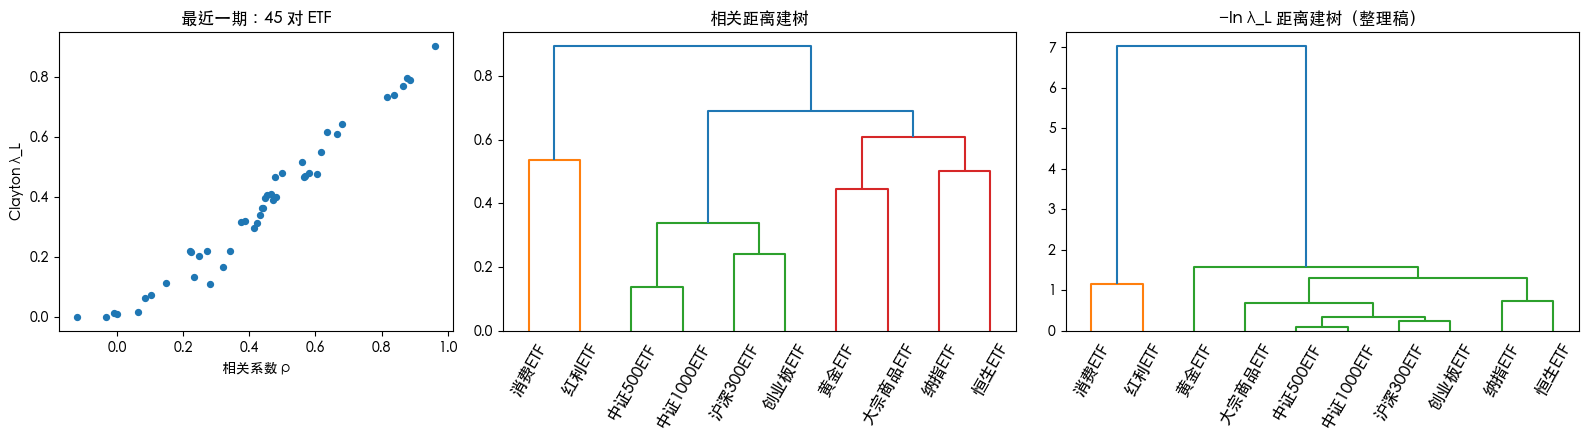

In [4]:
W = R.loc[:month_ends[-1]].tail(LOOKBACK)
lam, rho = lower_tail_matrix(W), W.corr()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
axes[0].scatter(rho.values[iu], lam.values[iu], s=18)
axes[0].set_xlabel("相关系数 ρ"); axes[0].set_ylabel("Clayton λ_L"); axes[0].set_title("最近一期：45 对 ETF")
dendrogram(tree(corr_distance(W), "ward"), labels=list(W.columns), ax=axes[1], leaf_rotation=60)
axes[1].set_title("相关距离建树")
dendrogram(tree(tail_distance(lam, "log"), "ward"), labels=list(W.columns), ax=axes[2], leaf_rotation=60)
axes[2].set_title("−ln λ_L 距离建树（整理稿）")
plt.tight_layout(); plt.show()

**判读**：λ_L 与 ρ 的秩相关平均约 0.98 —— λ_L 几乎就是相关系数的单调变换。
用线性距离 1−λ 建的树与相关距离的树基本相同；整理稿的 −ln λ 距离与相关树差异稍大，
主要因为 λ=0 的资产对（多为黄金与其他资产）在对数下被推到同一个很大的距离上。
这与中金那篇的发现一致：短窗口的单参数 Clayton λ 主要反映普通相关。

---
# B · arctan 合成公式有多准？

每季度末取过去 250 天，对 45 对 ETF、三种权重（25/75、50/50、75/25），
计算两资产组合的**真实历史 ES**（直接由组合收益算出，作为标准答案），与四种近似比较：

| 近似 | 用到的信息 |
|---|---|
| arctan 公式（整理稿） | 两资产 ES、λ_L 距离 |
| 线性加权 | 两资产 ES（不考虑分散效果，是上界） |
| 正态近似 | 组合均值与方差 |
| 相关系数合成 | 两资产 ES、普通相关系数：√(w1²ES1² + w2²ES2² + 2w1w2ρ·ES1·ES2) |

最后一种不含任何尾部相关信息，用来判断 λ_L 在「合成」这一步有没有额外价值。

In [5]:
rows = []
for t in month_ends[::3]:
    W = R.loc[:t].tail(LOOKBACK)
    D = tail_distance(lower_tail_matrix(W), "log")
    tr = {c: es_hist(W[c]) for c in W}
    for i, j in zip(*iu):
        a, b = W.columns[i], W.columns[j]
        rho_ab = W[a].corr(W[b])
        for w1 in (0.25, 0.5, 0.75):
            w2 = 1 - w1
            p = w1 * W[a] + w2 * W[b]
            rows.append({"ρ": rho_ab, "真实ES": es_hist(p),
                         "arctan 公式": two_asset_tr(w1, tr[a], tr[b], D.loc[a, b]),
                         "线性加权": w1 * tr[a] + w2 * tr[b],
                         "正态近似": -p.mean() + p.std() * norm.pdf(norm.ppf(.95)) / .05,
                         "相关系数合成": np.sqrt((w1 * tr[a]) ** 2 + (w2 * tr[b]) ** 2 + 2 * w1 * w2 * rho_ab * tr[a] * tr[b])})
partB = pd.DataFrame(rows)
methods = ["arctan 公式", "线性加权", "正态近似", "相关系数合成"]
pd.DataFrame({m: {"相对误差中位数（绝对值）": (partB[m] / partB["真实ES"] - 1).abs().median(),
                  "平均偏差": (partB[m] / partB["真实ES"] - 1).mean(),
                  "与真实 ES 的秩相关": spearmanr(partB[m], partB["真实ES"])[0]} for m in methods}).T.style.format("{:.3f}")

,相对误差中位数（绝对值）,平均偏差,与真实 ES 的秩相关
arctan 公式,0.022,0.037,0.989
线性加权,0.108,0.143,0.965
正态近似,0.112,-0.095,0.950
相关系数合成,0.020,-0.010,0.996


In [6]:
partB["相关系数分组"] = pd.cut(partB["ρ"], [-0.3, 0.2, 0.5, 0.7, 1.0])
partB.groupby("相关系数分组", observed=True).apply(
    lambda g: pd.Series({m: (g[m] / g["真实ES"] - 1).mean() for m in methods})).style.format("{:+.1%}")

,arctan 公式,线性加权,正态近似,相关系数合成
相关系数分组,,,,
"(-0.3, 0.2]",+10.8%,+28.3%,-9.8%,-0.2%
"(0.2, 0.5]",+2.8%,+14.3%,-10.9%,-1.6%
"(0.5, 0.7]",+0.4%,+8.0%,-7.6%,-1.4%
"(0.7, 1.0]",-0.5%,+3.3%,-9.1%,-0.7%


**判读**：

- arctan 公式确实是不错的近似：中位误差约 2%，明显好于线性加权（高估约 14%）和正态近似（低估约 10%，没考虑厚尾）。
- 但完全不用尾部信息的「相关系数合成」同样准确，而且偏差更小、排序更准。
  λ_L 在合成这一步没有带来超出普通相关系数的价值。
- arctan 公式在低相关的资产对上系统性高估约 10%，即低估了分散效果。

---
# C · 样本外配置表现

每月末用过去 250 个交易日计算权重，下一交易日起持有一个月（期间每日再平衡到目标权重），不计交易成本。

| 方法 | 距离 | 风险度量 | 权重上限 |
|---|---|---|---|
| 等权 | — | — | 10% |
| 波动率倒数 | — | 波动率 | 无 |
| 最小方差 | — | 方差 | 20% |
| HRP-相关 / HRP-尾部 | 相关系数 / 1−λ_L | 方差（递归二分） | 无（原始算法） |
| HRP-相关(≤20%) / HRP-尾部(≤20%) | 同上 | 同上 | 20%，超出部分按比例分给其他资产 |
| 最小ES | — | 历史 ES（线性规划） | 20% |
| 整理稿方法 | −ln λ_L，Ward | arctan 递归合成 | 0.01%–20% |

In [7]:
tail_lin = lambda W: tail_distance(lower_tail_matrix(W), "linear")
STRATS = {
    "等权": equal_weights,
    "波动率倒数": inverse_vol,
    "最小方差": min_variance,
    "HRP-相关": lambda W: hrp_weights(W),
    "HRP-尾部": lambda W: hrp_weights(W, tail_lin(W)),
    "HRP-相关(≤20%)": lambda W: cap_weights(hrp_weights(W)),
    "HRP-尾部(≤20%)": lambda W: cap_weights(hrp_weights(W, tail_lin(W))),
    "最小ES": min_cvar,
    "整理稿方法": nesc_weights,
}
port, weights = rolling_backtest(R, STRATS, lookback=LOOKBACK)

def table(port, weights, cost_bp=0.0):
    rows = {}
    for c in port:
        r = port[c].copy()
        if cost_bp:
            W = weights[c]
            tc = W.diff().abs().sum(axis=1).fillna(W.abs().sum(axis=1)) * cost_bp / 1e4
            first_day = {t: port.index[port.index > t][0] for t in W.index if (port.index > t).any()}
            for t, d in first_day.items():
                r.loc[d] -= tc.loc[t]
        s = perf_stats(r)
        s["样本外日 ES95"] = es_hist(r)
        s["月均单边换手"] = turnover(weights[c])
        rows[c] = s
    return pd.DataFrame(rows).T

FMT = {"年化收益": "{:.2%}", "年化波动": "{:.2%}", "最大回撤": "{:.2%}", "样本外日 ES95": "{:.2%}",
       "月均单边换手": "{:.1%}", "收益波动比": "{:.2f}", "超额夏普": "{:.2f}", "卡玛比率": "{:.2f}"}
print(f"回测区间 {port.index.min():%Y-%m-%d} ~ {port.index.max():%Y-%m-%d}")
table(port, weights).style.format(FMT)

回测区间 2018-02-01 ~ 2026-10-16


,年化收益,年化波动,收益波动比,超额夏普,最大回撤,卡玛比率,样本外日 ES95,月均单边换手
等权,7.46%,15.83%,0.47,0.34,-22.52%,0.33,2.39%,0.0%
波动率倒数,7.76%,13.92%,0.56,0.41,-19.91%,0.39,2.10%,1.4%
最小方差,7.62%,12.04%,0.63,0.47,-18.16%,0.42,1.83%,3.4%
HRP-相关,10.82%,11.06%,0.98,0.80,-15.01%,0.72,1.67%,5.9%
HRP-尾部,11.07%,11.01%,1.01,0.82,-15.26%,0.73,1.68%,5.7%
HRP-相关(≤20%),7.99%,12.87%,0.62,0.47,-18.88%,0.42,1.95%,4.7%
HRP-尾部(≤20%),8.16%,12.90%,0.63,0.48,-19.26%,0.42,1.97%,4.6%
最小ES,7.93%,12.62%,0.63,0.47,-21.18%,0.37,1.92%,6.6%
整理稿方法,6.83%,12.60%,0.54,0.38,-21.90%,0.31,1.91%,5.4%


In [8]:
pd.DataFrame({k: v.mean() for k, v in weights.items()}).style.format("{:.1%}").background_gradient(axis=None, cmap="Blues")

,等权,波动率倒数,最小方差,HRP-相关,HRP-尾部,HRP-相关(≤20%),HRP-尾部(≤20%),最小ES,整理稿方法
沪深300ETF,10.0%,11.4%,14.6%,6.8%,7.2%,9.4%,10.1%,15.3%,18.6%
中证500ETF,10.0%,9.2%,7.7%,4.8%,4.5%,6.8%,6.6%,4.9%,6.4%
中证1000ETF,10.0%,7.9%,0.9%,3.6%,3.2%,5.0%,4.5%,1.0%,0.1%
创业板ETF,10.0%,6.4%,0.9%,3.1%,3.1%,4.4%,4.5%,3.2%,1.0%
消费ETF,10.0%,7.9%,5.3%,4.8%,4.7%,6.7%,6.7%,6.8%,4.8%
黄金ETF,10.0%,15.2%,18.6%,36.1%,36.0%,18.6%,18.9%,18.5%,18.2%
纳指ETF,10.0%,8.4%,16.2%,9.6%,9.2%,13.2%,13.1%,15.7%,9.8%
恒生ETF,10.0%,10.1%,12.4%,9.1%,8.2%,12.5%,11.5%,11.3%,16.2%
红利ETF,10.0%,15.9%,20.0%,17.7%,19.1%,16.7%,17.1%,20.0%,20.0%
大宗商品ETF,10.0%,7.6%,3.5%,4.5%,4.9%,6.6%,7.1%,3.5%,4.8%


**注意**：原始 HRP 没有权重上限，黄金平均拿到约三分之一的仓位。黄金这几年大涨，
所以不设上限的 HRP 表现好有相当部分来自这一点；和其他方法比较时应看加了 20% 上限的版本。

### C.1 关键比较是否显著

约 9 年的日度样本下，超额夏普的标准误差大约在 0.3 左右。用分块自助法（20 日一块，2000 次）
检验三组关键比较的超额夏普差值：

In [9]:
pairs = [("HRP-尾部(≤20%)", "HRP-相关(≤20%)", "尾部距离 vs 相关距离"),
         ("整理稿方法", "最小ES", "整理稿方法 vs 直接最小化 ES"),
         ("整理稿方法", "最小方差", "整理稿方法 vs 最小方差")]
rows = {}
for a, b, label in pairs:
    pt, lo, hi, p_le0 = block_bootstrap_sharpe_diff(port[a], port[b])
    rows[label] = {"超额夏普差": pt, "95% 区间下限": lo, "95% 区间上限": hi, "差值≤0 的比例": p_le0}
pd.DataFrame(rows).T.style.format({"超额夏普差": "{:+.2f}", "95% 区间下限": "{:+.2f}",
                                   "95% 区间上限": "{:+.2f}", "差值≤0 的比例": "{:.0%}"})

,超额夏普差,95% 区间下限,95% 区间上限,差值≤0 的比例
尾部距离 vs 相关距离,+0.01,-0.04,+0.06,33%
整理稿方法 vs 直接最小化 ES,-0.08,-0.24,+0.06,86%
整理稿方法 vs 最小方差,-0.08,-0.24,+0.05,89%


**判读**：三组差异都不显著。尾部距离与相关距离的 HRP 几乎没有差别；
整理稿方法比最小 ES、最小方差略差（超额夏普低约 0.08），但 95% 区间包含 0。

### C.2 整理稿方法在估计窗口内找到的组合，ES 有多低？

最小ES 在每个估计窗口内都是历史 ES 的最优解。比较各方法在**同一窗口内**的组合历史 ES，
可以看出整理稿方法的「最小化合成 TR」离真正的最小 ES 有多远。

In [10]:
gap = {}
for name in ["整理稿方法", "最小方差", "HRP-相关(≤20%)", "等权"]:
    vals = []
    for t, w in weights[name].iterrows():
        Wn = R.loc[:t].tail(LOOKBACK)
        vals.append(es_hist(Wn @ w) / es_hist(Wn @ weights["最小ES"].loc[t]) - 1)
    gap[name] = pd.Series(vals).describe()[["mean", "50%", "max"]]
pd.DataFrame(gap).T.rename(columns={"mean": "平均", "50%": "中位数", "max": "最大"}).style.format("{:+.1%}")

,平均,中位数,最大
整理稿方法,+5.3%,+3.2%,+24.8%
最小方差,+2.3%,+1.7%,+10.0%
HRP-相关(≤20%),+9.7%,+9.3%,+17.4%
等权,+38.8%,+37.1%,+63.5%


**判读**：在同一个估计窗口内，整理稿方法选出的组合，历史 ES 平均比最优解高约 5%，最多高约 25%；
甚至不如只看方差的最小方差组合（平均高约 2%）。把 arctan 合成公式当作优化目标，
并不能有效地把组合的真实 ES 压下来 —— B 部分看到的「两资产近似不错」，
在十个资产、沿树多层合成、再交给优化器之后，误差被放大了。

### C.3 稳健性

依次改变：交易成本 10bp（单边）；回看期 500 日；整理稿方法的单资产 TR 改用 GPD 估计的 ES。

In [11]:
core = ["等权", "最小方差", "HRP-相关(≤20%)", "HRP-尾部(≤20%)", "最小ES", "整理稿方法"]
robust = {"主口径": table(port, weights)["超额夏普"],
          "计 10bp 成本": table(port, weights, cost_bp=10)["超额夏普"]}
p500, w500 = rolling_backtest(R, {k: STRATS[k] for k in core}, lookback=500)
robust["回看 500 日"] = table(p500, w500)["超额夏普"]
p_gpd, w_gpd = rolling_backtest(R, {"整理稿方法": lambda W: nesc_weights(W, es_func=es_gpd)}, lookback=LOOKBACK)
robust["主口径"].loc["整理稿方法(GPD)"] = table(p_gpd, w_gpd)["超额夏普"].iloc[0]
pd.DataFrame(robust).loc[core + ["整理稿方法(GPD)"]].style.format("{:.2f}", na_rep="—")

,主口径,计 10bp 成本,回看 500 日
等权,0.34,0.34,0.51
最小方差,0.47,0.46,0.62
HRP-相关(≤20%),0.47,0.46,0.68
HRP-尾部(≤20%),0.48,0.47,0.71
最小ES,0.47,0.46,0.58
整理稿方法,0.38,0.37,0.52
整理稿方法(GPD),0.36,—,—


注：回看 500 日的回测从更晚的时点开始，样本区间与主口径不同，只宜在同一列内比较。

**判读**：计入交易成本、改用 500 日回看、单资产 ES 改用 GPD，排序都没有实质变化：
尾部距离 HRP 与相关距离 HRP 相当，整理稿方法始终不优于最小方差与最小 ES。

---
# 结论

| 问题 | 结论 |
|---|---|
| A. λ_L 距离与相关距离 | **几乎相同**。λ_L 与 ρ 的秩相关约 0.98；1−λ 距离的树与相关距离的树基本一致 |
| B. arctan 公式的准确度 | **不错，但不需要尾部信息**。中位误差约 2%；只用普通相关系数的合成公式同样准、偏差更小 |
| C. 样本外配置 | 尾部距离的 HRP 与相关距离的 HRP 无显著差别；整理稿方法不优于直接最小化 ES 或最小方差（差异不显著） |
| C. 作为优化目标 | 整理稿方法选出的组合，窗口内历史 ES 平均比最优高约 5%，还不如最小方差组合 |

在这 10 只 ETF 上，用 Clayton 下尾相关替代普通相关，无论在聚类、风险合成还是样本外配置上都没有带来可检验的增量。